In [1]:
# ==============================================================================
# CÉLULA 1: Importações, Seed Fixa e Carregamento dos Dados (P1: SIH/SUS + IBGE)
# ==============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder

from utils import (
    SEED,
    ATRIBUTOS_CATEGORICOS,
    ALVO_CLASSIFICACAO,
    carregar_ou_gerar_dados_p1,
    kfold_indices,
)

np.random.seed(SEED)

df = carregar_ou_gerar_dados_p1(forcar_geracao=True)
print(f"Total de registros (N): {len(df)}")
print(f"Distribuição da variável-alvo '{ALVO_CLASSIFICACAO}':")
print(df[ALVO_CLASSIFICACAO].value_counts( normalize=False))
print(df[ALVO_CLASSIFICACAO].value_counts(normalize=True).round(4))
df[ATRIBUTOS_CATEGORICOS + [ALVO_CLASSIFICACAO]].head()

Total de registros (N): 800
Distribuição da variável-alvo 'desfecho_grave':
desfecho_grave
0    480
1    320
Name: count, dtype: int64
desfecho_grave
0    0.6
1    0.4
Name: proportion, dtype: float64


,triagem_clinica,carater_atendimento,faixa_etaria,saneamento_ibge,tempo_permanencia,renda_mun_ibge,desfecho_grave
0,Leve,Eletivo,Adulto,Adequado,Media_4_7d,Media_Alta,0
1,Leve,Eletivo,Adulto,Parcial,Media_4_7d,Alta,0
2,Moderada,Emergencia_Severa,Idoso_75_Mais,Parcial,Curta_1_3d,Media_Alta,0
3,Critica,Eletivo,Jovem,Adequado,Curta_1_3d,Media_Baixa,0
4,Moderada,Emergencia_Severa,Adulto,Parcial,Curta_1_3d,Media_Alta,0


In [2]:
# ==============================================================================
# CÉLULA 2: Implementação do LEARN-DECISION-TREE do Zero (Listing 1 do PDF)
# ==============================================================================
def entropia(exemplos, alvo=ALVO_CLASSIFICACAO):
    """
    FUNCAO Entropia(exemplos):
      SE vazio: RETORNA 0
      p <- frequencia relativa das classes
      RETORNA -soma(p * log2(p))
    """
    if len(exemplos) == 0:
        return 0.0
    contagens = exemplos[alvo].value_counts().values
    p = contagens / len(exemplos)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))


def ganho(exemplos, atributo, alvo=ALVO_CLASSIFICACAO):
    """
    FUNCAO Ganho(exemplos, atributo):
      H_pai <- Entropia(exemplos)
      H_filhos <- soma_{v} (|sub_v| / |exemplos|) * Entropia(sub_v)
      RETORNA H_pai - H_filhos
    """
    h_pai = entropia(exemplos, alvo)
    n_total = len(exemplos)
    if n_total == 0:
        return 0.0

    h_filhos = 0.0
    for valor, sub_v in exemplos.groupby(atributo):
        peso = len(sub_v) / n_total
        h_filhos += peso * entropia(sub_v, alvo)

    return float(h_pai - h_filhos)


def classe_majoritaria(exemplos, alvo=ALVO_CLASSIFICACAO):
    """Retorna a classe mais frequente no conjunto de exemplos (desempate determinístico)."""
    contagem = Counter(exemplos[alvo])
    return sorted(contagem.items(), key=lambda x: (-x[1], x[0]))[0][0]


def arvore(exemplos, atributos, alvo=ALVO_CLASSIFICACAO, prof_atual=0, max_depth=None):
    """
    FUNCAO Arvore(exemplos, atributos) - LEARN-DECISION-TREE:
      SE classes uniformes: RETORNA classe
      SE atributos vazio (ou atingiu max_depth): RETORNA classe_majoritaria(exemplos)
      A <- argmax_{a} Ganho(exemplos, a)
      RETORNA NO(A, filhos={v: Arvore(sub_v, atributos - {A})})
    """
    classes_unicas = exemplos[alvo].unique()
    if len(classes_unicas) == 1:
        return int(classes_unicas[0])

    if len(atributos) == 0 or (max_depth is not None and prof_atual >= max_depth):
        return int(classe_majoritaria(exemplos, alvo))

    # Seleciona o atributo A que maximiza Ganho(exemplos, a)
    ganhos = {a: ganho(exemplos, a, alvo) for a in atributos}
    melhor_atrib = max(atributos, key=lambda a: ganhos[a])

    # Se ganho for nulo, retorna folha com classe majoritária
    if ganhos[melhor_atrib] <= 1e-12:
        return int(classe_majoritaria(exemplos, alvo))

    padrao_pai = int(classe_majoritaria(exemplos, alvo))
    novos_atributos = [a for a in atributos if a != melhor_atrib]

    filhos = {}
    for valor, sub_v in exemplos.groupby(melhor_atrib):
        if len(sub_v) == 0:
            filhos[valor] = padrao_pai
        else:
            filhos[valor] = arvore(
                sub_v,
                novos_atributos,
                alvo=alvo,
                prof_atual=prof_atual + 1,
                max_depth=max_depth,
            )

    return {
        "atributo": melhor_atrib,
        "ganho": round(ganhos[melhor_atrib], 4),
        "padrao": padrao_pai,
        "filhos": filhos,
    }


def prever_exemplo(no, linha):
    """Realiza a predição recursiva de uma única instância na árvore induzida."""
    if not isinstance(no, dict):
        return no
    valor = linha.get(no["atributo"])
    if valor not in no["filhos"]:
        return no["padrao"]
    return prever_exemplo(no["filhos"][valor], linha)


def prever_arvore(modelo_arvore, df_teste):
    """Vetoriza a predição para todo o DataFrame de teste."""
    return np.array([prever_exemplo(modelo_arvore, row) for _, row in df_teste.iterrows()])


def calcular_profundidade(no):
    """Retorna a profundidade máxima da árvore induzida."""
    if not isinstance(no, dict):
        return 0
    return 1 + max(calcular_profundidade(filho) for filho in no["filhos"].values())

In [3]:
# ==============================================================================
# CÉLULA 3: Verificação dos Cálculos Manuais (3 Primeiros Níveis da Árvore)
# ==============================================================================
print("=== NÍVEL 1 (RAIZ) ===")
print(f"Entropia da Raiz H(S): {entropia(df):.4f} bits")
for a in ATRIBUTOS_CATEGORICOS:
    print(f"  Ganho(S, {a:20s}) = {ganho(df, a):.4f} bits")

print("\n=== NÍVEL 2 (Ramo triagem_clinica == 'Moderada') ===")
df_mod = df[df["triagem_clinica"] == "Moderada"]
print(f"H(S_Moderada): {entropia(df_mod):.4f} bits | N = {len(df_mod)}")
for a in [col for col in ATRIBUTOS_CATEGORICOS if col != "triagem_clinica"]:
    print(f"  Ganho(S_Moderada, {a:20s}) = {ganho(df_mod, a):.4f} bits")

print("\n=== NÍVEL 2 (Ramo triagem_clinica == 'Critica') ===")
df_crit = df[df["triagem_clinica"] == "Critica"]
print(f"H(S_Critica): {entropia(df_crit):.4f} bits | N = {len(df_crit)}")
for a in [col for col in ATRIBUTOS_CATEGORICOS if col != "triagem_clinica"]:
    print(f"  Ganho(S_Critica, {a:20s}) = {ganho(df_crit, a):.4f} bits")

print("\n=== NÍVEL 3 (Ramo triagem_clinica == 'Moderada' E carater_atendimento == 'Emergencia_Severa') ===")
df_mod_emerg = df_mod[df_mod["carater_atendimento"] == "Emergencia_Severa"]
print(f"H(S_Mod_Emerg): {entropia(df_mod_emerg):.4f} bits | N = {len(df_mod_emerg)}")
for a in [col for col in ATRIBUTOS_CATEGORICOS if col not in ("triagem_clinica", "carater_atendimento")]:
    print(f"  Ganho(S_Mod_Emerg, {a:20s}) = {ganho(df_mod_emerg, a):.4f} bits")

=== NÍVEL 1 (RAIZ) ===
Entropia da Raiz H(S): 0.9710 bits
  Ganho(S, triagem_clinica     ) = 0.1470 bits
  Ganho(S, carater_atendimento ) = 0.1398 bits
  Ganho(S, faixa_etaria        ) = 0.1578 bits
  Ganho(S, saneamento_ibge     ) = 0.0815 bits
  Ganho(S, tempo_permanencia   ) = 0.1362 bits
  Ganho(S, renda_mun_ibge      ) = 0.0709 bits

=== NÍVEL 2 (Ramo triagem_clinica == 'Moderada') ===
H(S_Moderada): 0.9341 bits | N = 300
  Ganho(S_Moderada, carater_atendimento ) = 0.1726 bits
  Ganho(S_Moderada, faixa_etaria        ) = 0.1579 bits
  Ganho(S_Moderada, saneamento_ibge     ) = 0.0881 bits
  Ganho(S_Moderada, tempo_permanencia   ) = 0.1242 bits
  Ganho(S_Moderada, renda_mun_ibge      ) = 0.0788 bits

=== NÍVEL 2 (Ramo triagem_clinica == 'Critica') ===
H(S_Critica): 0.8813 bits | N = 250
  Ganho(S_Critica, carater_atendimento ) = 0.1524 bits
  Ganho(S_Critica, faixa_etaria        ) = 0.1499 bits
  Ganho(S_Critica, saneamento_ibge     ) = 0.0413 bits
  Ganho(S_Critica, tempo_permanenci

In [4]:
# ==============================================================================
# CÉLULA 4: Validação Cruzada 5-Fold e Comparação com Scikit-Learn (Tarefas 5 e 6)
# ==============================================================================
splits = kfold_indices(len(df), k=5, seed=SEED)

resultados_profundidade = []

for max_d in [1, 2, 3, 4, 5, 6, None]:
    rotulo_d = "Sem Poda (Completa)" if max_d is None else f"Profundidade {max_d}"
    acc_treino_zero, acc_teste_zero = [], []
    acc_treino_sk, acc_teste_sk = [], []

    for idx_tr, idx_te in splits:
        df_tr = df.iloc[idx_tr].reset_index(drop=True)
        df_te = df.iloc[idx_te].reset_index(drop=True)

        # 1. LEARN-DECISION-TREE (Do Zero)
        modelo_zero = arvore(df_tr, ATRIBUTOS_CATEGORICOS, max_depth=max_d)
        pred_tr_zero = prever_arvore(modelo_zero, df_tr)
        pred_te_zero = prever_arvore(modelo_zero, df_te)

        acc_treino_zero.append(np.mean(pred_tr_zero == df_tr[ALVO_CLASSIFICACAO].values))
        acc_teste_zero.append(np.mean(pred_te_zero == df_te[ALVO_CLASSIFICACAO].values))

        # 2. Scikit-Learn DecisionTreeClassifier
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        X_tr = enc.fit_transform(df_tr[ATRIBUTOS_CATEGORICOS])
        X_te = enc.transform(df_te[ATRIBUTOS_CATEGORICOS])
        y_tr = df_tr[ALVO_CLASSIFICACAO].values
        y_te = df_te[ALVO_CLASSIFICACAO].values

        clf_sk = DecisionTreeClassifier(criterion="entropy", max_depth=max_d, random_state=SEED)
        clf_sk.fit(X_tr, y_tr)
        acc_treino_sk.append(clf_sk.score(X_tr, y_tr))
        acc_teste_sk.append(clf_sk.score(X_te, y_te))

    resultados_profundidade.append({
        "Configuração": rotulo_d,
        "Max_Depth": 6 if max_d is None else max_d,
        "Treino_Do_Zero (%)": round(100 * np.mean(acc_treino_zero), 2),
        "Teste_5Fold_Do_Zero (%)": round(100 * np.mean(acc_teste_zero), 2),
        "Desvio_Do_Zero (%)": round(100 * np.std(acc_teste_zero), 2),
        "Treino_Sklearn (%)": round(100 * np.mean(acc_treino_sk), 2),
        "Teste_5Fold_Sklearn (%)": round(100 * np.mean(acc_teste_sk), 2),
    })

df_res = pd.DataFrame(resultados_profundidade)
print(df_res.to_string(index=False))

       Configuração  Max_Depth  Treino_Do_Zero (%)  Teste_5Fold_Do_Zero (%)  Desvio_Do_Zero (%)  Treino_Sklearn (%)  Teste_5Fold_Sklearn (%)
     Profundidade 1          1               72.25                    70.12                2.03               72.50                    72.50
     Profundidade 2          2               78.25                    72.00                2.57               74.25                    73.12
     Profundidade 3          3               83.97                    75.50                2.18               76.06                    72.38
     Profundidade 4          4               90.03                    80.12                3.90               79.72                    74.13
     Profundidade 5          5               95.53                    78.75                4.83               83.00                    77.75
     Profundidade 6          6               97.50                    78.63                4.53               85.94                    79.88
Sem Poda (Com

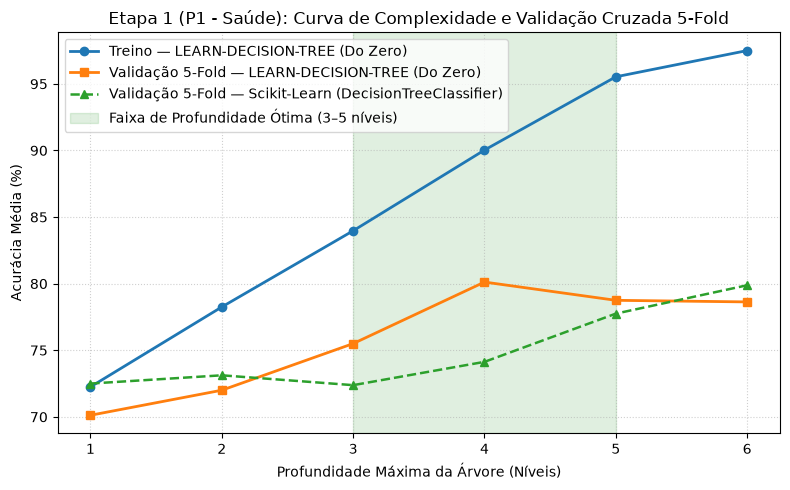

In [5]:
# ==============================================================================
# CÉLULA 5: Gráfico de Profundidade vs. Acurácia (Treino vs. Validação 5-Fold)
# ==============================================================================
df_plot = df_res[df_res["Configuração"] != "Sem Poda (Completa)"]

plt.figure(figsize=(8, 5))
plt.plot(df_plot["Max_Depth"], df_plot["Treino_Do_Zero (%)"], marker="o", linewidth=2, label="Treino — LEARN-DECISION-TREE (Do Zero)")
plt.plot(df_plot["Max_Depth"], df_plot["Teste_5Fold_Do_Zero (%)"], marker="s", linewidth=2, label="Validação 5-Fold — LEARN-DECISION-TREE (Do Zero)")
plt.plot(df_plot["Max_Depth"], df_plot["Teste_5Fold_Sklearn (%)"], marker="^", linestyle="--", linewidth=1.8, label="Validação 5-Fold — Scikit-Learn (DecisionTreeClassifier)")
plt.axvspan(3, 5, color="green", alpha=0.12, label="Faixa de Profundidade Ótima (3–5 níveis)")
plt.xlabel("Profundidade Máxima da Árvore (Níveis)")
plt.ylabel("Acurácia Média (%)")
plt.title("Etapa 1 (P1 - Saúde): Curva de Complexidade e Validação Cruzada 5-Fold")
plt.xticks([1, 2, 3, 4, 5, 6])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("fig_etapa1_curva_profundidade.png", dpi=300)
plt.show()